# 01 — Data description and exploratory data analysis
**Owner: Harisson Tenu (Data & EDA)**

Competition: [Predicting Airline Satisfaction — Kaggle Playground Series S6E10](https://www.kaggle.com/competitions/playground-series-s6e10)

Goal: predict whether a passenger is **satisfied** (`satisfaction = True`) from their
profile, their flight and the 1–5 ratings they gave to 13 services.

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.preprocess import (load_data, TARGET, RATING_COLS, DELAY_COLS,
                            CATEGORICAL_COLS)

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.edgecolor": "#8a8984",
})
SAT, UNSAT, NEUTRAL = "#2a78d6", "#eb6834", "#8a8984"   # satisfied / not satisfied / single series
FIG = "../figures/"

train, test = load_data()
print("train:", train.shape, " test:", test.shape)
train.head()

train: (699635, 23)  test: (299844, 22)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


## 1. Data description
The data is synthetic: Kaggle generated it from the original
[Airline Passenger Satisfaction](https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction)
survey with a deep-learning model, so distributions are close to, but not identical to, the original.

| Group | Columns | Type | Meaning |
|---|---|---|---|
| ID | `id` | int | row identifier (not a feature) |
| Passenger | `Age` | numeric | age in years |
| | `Gender` | binary categorical | Female / Male |
| | `Customer Type` | binary categorical | Loyal / disloyal customer of the airline |
| Trip | `Type of Travel` | binary categorical | Business travel / Personal travel |
| | `Class` | categorical (3, ordered) | Eco, Eco Plus, Business |
| | `Flight Distance` | numeric | flight length in miles |
| | `Departure Delay in Minutes`, `Arrival Delay in Minutes` | numeric | delays in minutes |
| Service ratings | 13 columns: wifi, time convenience, online booking, gate location, food & drink, online boarding, seat comfort, entertainment, on-board service, leg room, baggage handling, check-in, cleanliness | ordinal 0–5 | 1 = worst, 5 = best, **0 = not applicable** |
| **Target** | `satisfaction` | binary | True = satisfied, False = neutral or dissatisfied |

In [2]:
summary = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "n_unique": train.nunique(),
    "n_missing": train.isna().sum(),
    "min": train.min(numeric_only=True),
    "max": train.max(numeric_only=True),
})
summary

,dtype,n_unique,n_missing,min,max
Age,int64,75,0,7.0,85.0
Arrival Delay in Minutes,float64,168,292,0.0,491.0
Baggage handling,int64,5,0,1.0,5.0
Checkin service,int64,6,0,0.0,5.0
Class,str,3,0,NaN,NaN
Cleanliness,int64,6,0,0.0,5.0
Customer Type,str,2,0,NaN,NaN
Departure Delay in Minutes,int64,167,0,0.0,489.0
Departure/Arrival time convenient,int64,6,0,0.0,5.0
Ease of Online booking,int64,6,0,0.0,5.0


In [3]:
print("Duplicated rows (ignoring id):", train.drop(columns="id").duplicated().sum())
print("Test columns match train (minus target):",
      list(test.columns) == [c for c in train.columns if c != TARGET])

Duplicated rows (ignoring id): 0
Test columns match train (minus target): True


## 2. Target distribution

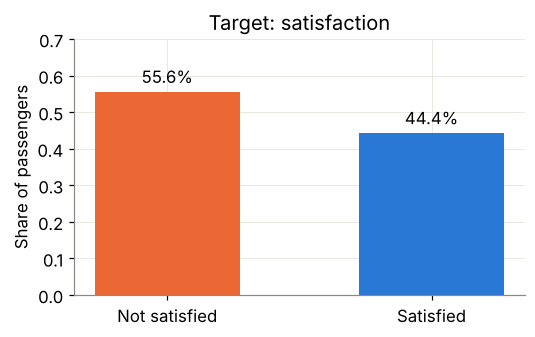

In [4]:
share = train[TARGET].value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(["Not satisfied", "Satisfied"], share.values, color=[UNSAT, SAT], width=0.55)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in share.values], padding=3)
ax.set_ylabel("Share of passengers"); ax.set_ylim(0, 0.7)
ax.set_title("Target: satisfaction")
fig.tight_layout(); fig.savefig(FIG + "target.png", dpi=150); plt.show()

**Finding:** 44.4% satisfied vs 55.6% not — mildly imbalanced, so no resampling is needed.
Because the competition scores predicted **probabilities** (see the sample submission), the metric
is ROC AUC, which is insensitive to this imbalance anyway.

## 3. Numeric features

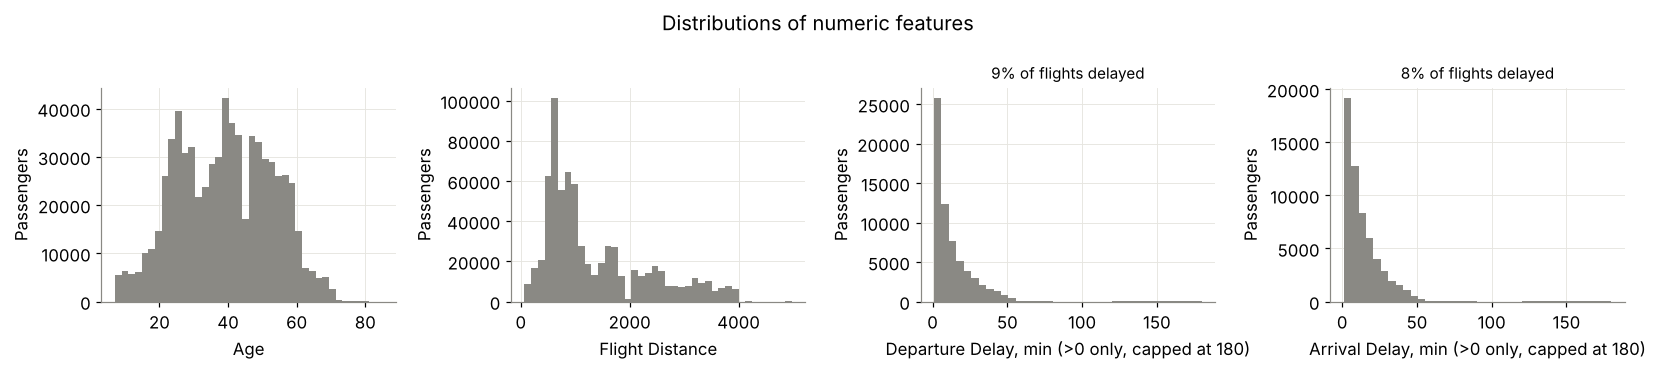

Departure Delay in Minutes    0.907833
Arrival Delay in Minutes      0.915356
Name: share of zero delays, dtype: float64
       Departure Delay in Minutes  Arrival Delay in Minutes
0.500                         0.0                       0.0
0.900                         0.0                       0.0
0.990                        30.0                      28.0
0.999                        52.0                      49.0


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, col in zip(axes, ["Age", "Flight Distance"] + DELAY_COLS):
    data = train[col].dropna()
    if "Delay" in col:
        delayed = data[data > 0]
        ax.hist(delayed.clip(upper=180), bins=36, color=NEUTRAL)
        ax.set_xlabel(f"{col.replace(' in Minutes', '')}, min (>0 only, capped at 180)")
        ax.set_title(f"{(data > 0).mean():.0%} of flights delayed", fontsize=10)
    else:
        ax.hist(data, bins=40, color=NEUTRAL); ax.set_xlabel(col)
    ax.set_ylabel("Passengers")
fig.suptitle("Distributions of numeric features")
fig.tight_layout(); fig.savefig(FIG + "numeric_hist.png", dpi=150); plt.show()

print((train[DELAY_COLS] == 0).mean().rename("share of zero delays"))
print(train[DELAY_COLS].quantile([0.5, 0.9, 0.99, 0.999]))

**Findings:**
* `Age` is spread from 7 to 85 with most passengers between 25 and 60.
* `Flight Distance` is right-skewed: many short flights, a long tail up to ~5,000 miles.
* Delays are extremely skewed: ~91% of flights have **zero** departure delay and the 99th
  percentile is 30 min, but the max is ~490 min. The plots show only delayed flights; among
  them most delays are under an hour. We use `log1p` for linear models; trees don't need it.

## 4. Categorical features

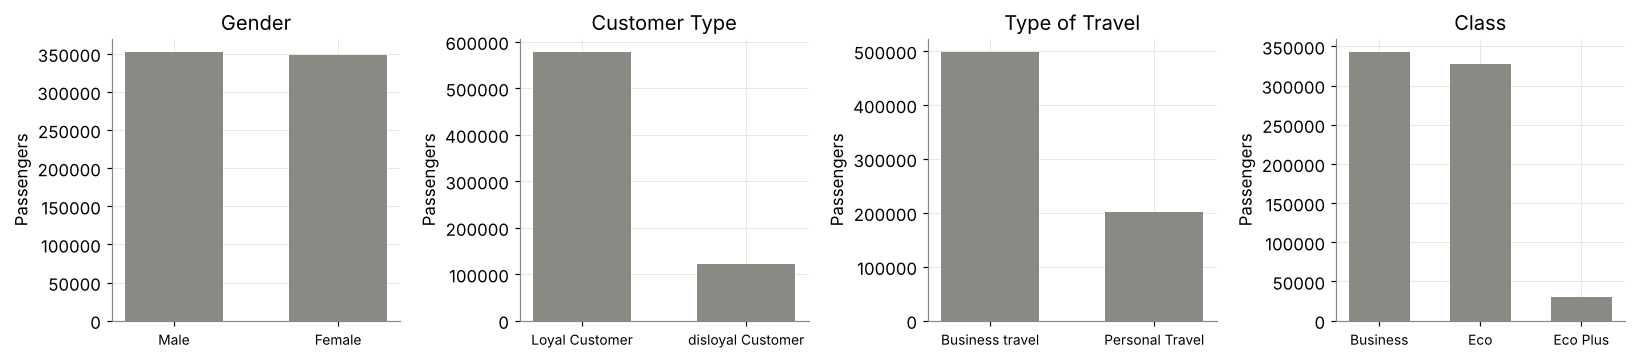

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, col in zip(axes, CATEGORICAL_COLS):
    vc = train[col].value_counts()
    ax.bar(vc.index.astype(str), vc.values, color=NEUTRAL, width=0.6)
    ax.set_title(col); ax.set_ylabel("Passengers")
    ax.tick_params(axis="x", labelsize=9)
fig.tight_layout(); fig.savefig(FIG + "categorical_bars.png", dpi=150); plt.show()

**Findings:** Gender is balanced. Most passengers are loyal (82%) and travel for business (71%).
`Class` is dominated by Business and Eco; Eco Plus is small (4%).

## 5. Service ratings

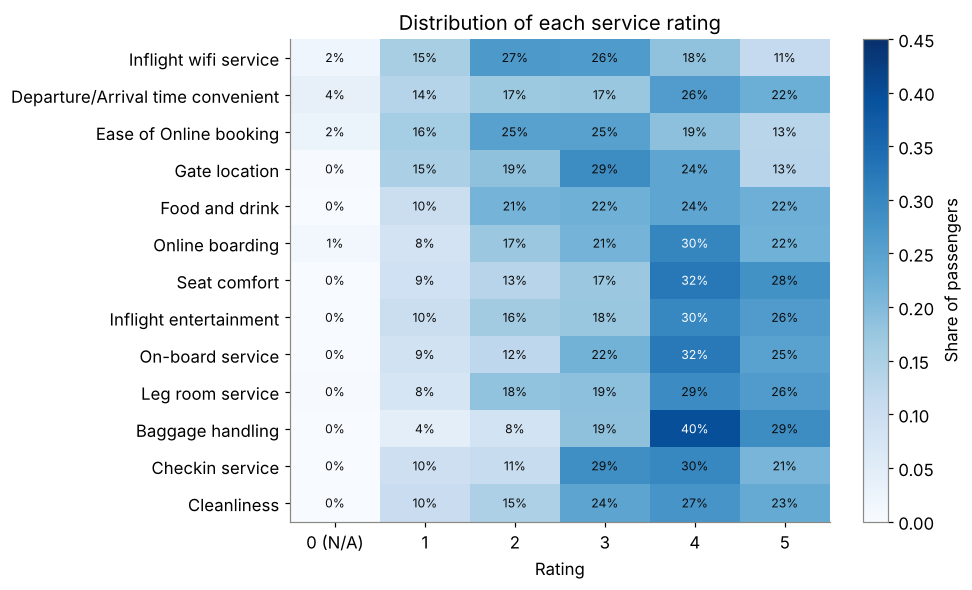

In [7]:
counts = pd.DataFrame({c: train[c].value_counts(normalize=True) for c in RATING_COLS}).T.fillna(0)
counts = counts[[0, 1, 2, 3, 4, 5]]
fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(counts.values, cmap="Blues", aspect="auto", vmin=0, vmax=0.45)
ax.set_xticks(range(6), ["0 (N/A)", "1", "2", "3", "4", "5"])
ax.set_yticks(range(len(RATING_COLS)), RATING_COLS)
ax.set_xlabel("Rating"); ax.grid(False)
for i in range(counts.shape[0]):
    for j in range(6):
        v = counts.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.3 else "#0b0b0b")
fig.colorbar(im, ax=ax, label="Share of passengers")
ax.set_title("Distribution of each service rating")
fig.tight_layout(); fig.savefig(FIG + "ratings_heatmap.png", dpi=150); plt.show()

**Findings:** Ratings are mostly 3–5. Zeros ("not applicable") appear mainly in wifi,
time convenience, online booking and online boarding (1–4% of rows) — services some
passengers simply didn't use. Zeros are kept as a separate level, not treated as missing.

## 6. Relations with the target

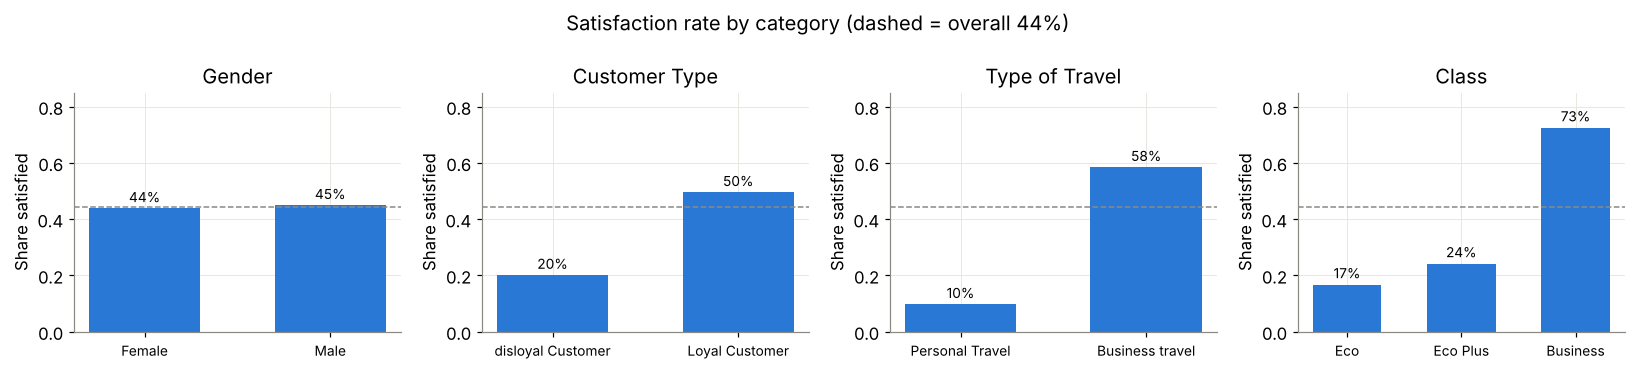

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, col in zip(axes, CATEGORICAL_COLS):
    rate = train.groupby(col)[TARGET].mean().sort_values()
    bars = ax.bar(rate.index.astype(str), rate.values, color=SAT, width=0.6)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in rate.values], padding=2, fontsize=9)
    ax.axhline(train[TARGET].mean(), color=NEUTRAL, ls="--", lw=1)
    ax.set_title(col); ax.set_ylabel("Share satisfied"); ax.set_ylim(0, 0.85)
    ax.tick_params(axis="x", labelsize=9)
fig.suptitle("Satisfaction rate by category (dashed = overall 44%)")
fig.tight_layout(); fig.savefig(FIG + "cat_vs_target.png", dpi=150); plt.show()

**Findings:** The trip context matters a lot:
* **Business class: 73% satisfied** vs Eco 17% and Eco Plus 24%.
* **Business travel: 58%** vs personal travel only 10%.
* Loyal customers 50% vs disloyal 20%. Gender makes almost no difference.

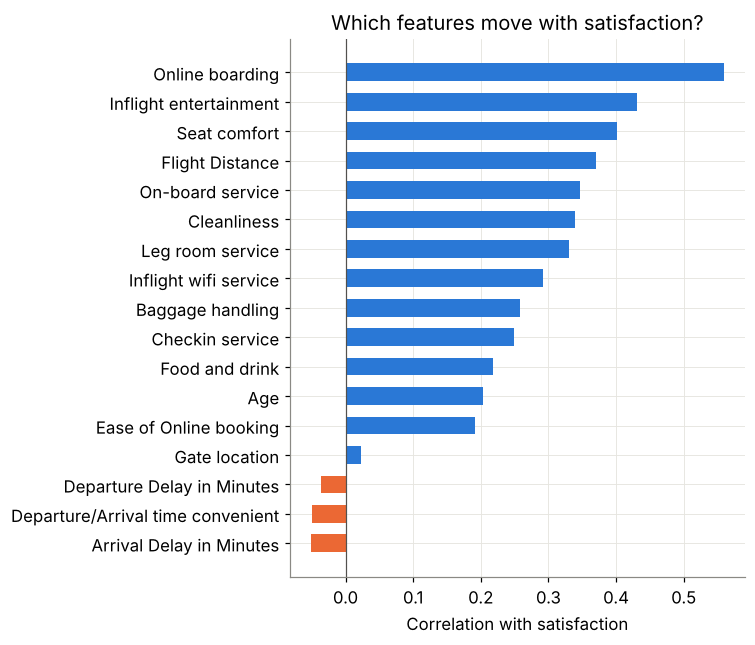

In [9]:
corr = (train[RATING_COLS + ["Age", "Flight Distance"] + DELAY_COLS]
        .corrwith(train[TARGET]).sort_values())
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(corr.index, corr.values, color=[SAT if v > 0 else UNSAT for v in corr.values], height=0.6)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlabel("Correlation with satisfaction")
ax.set_title("Which features move with satisfaction?")
fig.tight_layout(); fig.savefig(FIG + "corr_target.png", dpi=150); plt.show()

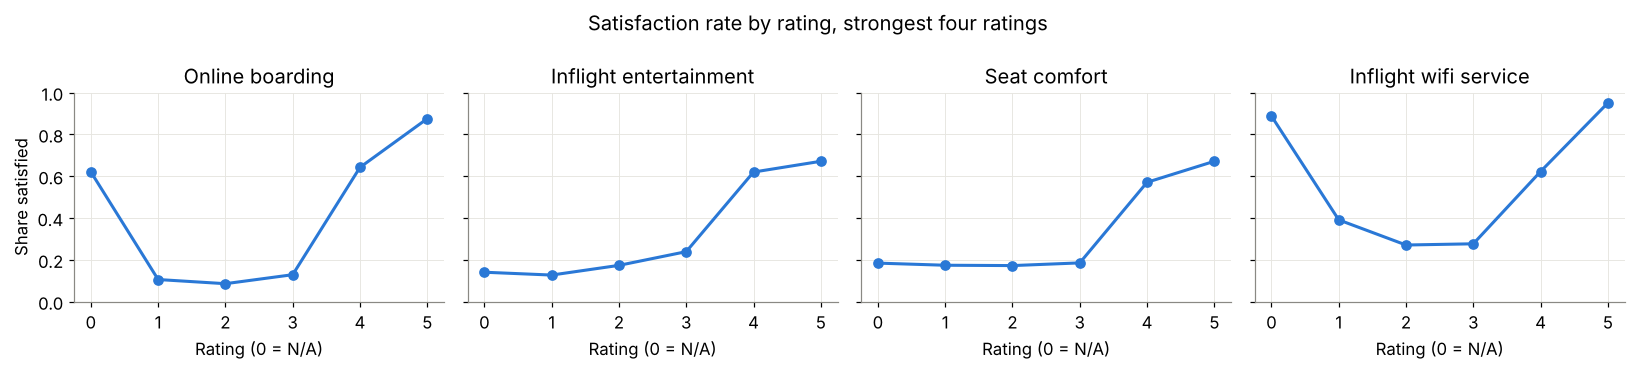

In [10]:
top = ["Online boarding", "Inflight entertainment", "Seat comfort", "Inflight wifi service"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, col in zip(axes, top):
    rate = train.groupby(col)[TARGET].mean()
    ax.plot(rate.index, rate.values, marker="o", ms=6, lw=2, color=SAT)
    ax.set_title(col); ax.set_xlabel("Rating (0 = N/A)"); ax.set_xticks(range(6))
axes[0].set_ylabel("Share satisfied"); axes[0].set_ylim(0, 1)
fig.suptitle("Satisfaction rate by rating, strongest four ratings")
fig.tight_layout(); fig.savefig(FIG + "top_ratings_vs_target.png", dpi=150); plt.show()

**Findings:**
* **Online boarding** is the single strongest signal (r = 0.56), followed by in-flight
  entertainment, seat comfort and flight distance (longer flights are more often business class).
* The effect of a rating is **not linear**: satisfaction jumps sharply at 4–5. Wifi has a
  U-shaped pattern — a rating of 5 means almost everyone is satisfied, and 0 (N/A) is also high.
  Tree models will capture this better than a linear model.
* The 0 = "not applicable" level behaves differently from a low rating: for online boarding
  it is 62% satisfied (vs ~10% for ratings 1–3), and for wifi it is 89%. So 0 must stay a
  separate level and must not be treated as a bad score or as missing.
* Delays barely correlate with satisfaction (r ≈ −0.04) because most delays are zero.

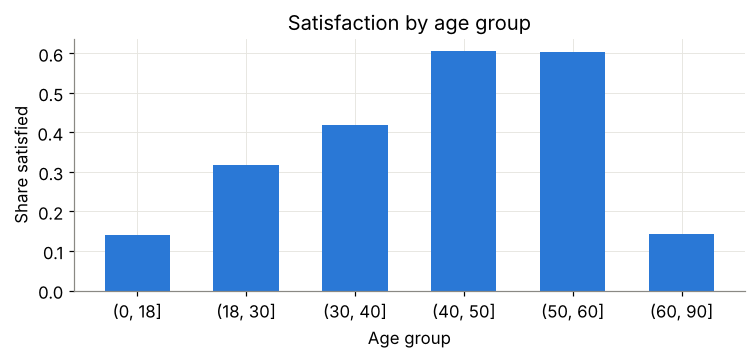

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.4))
bins = [0, 18, 30, 40, 50, 60, 90]
grp = train.groupby(pd.cut(train["Age"], bins), observed=True)[TARGET].mean()
ax.bar(grp.index.astype(str), grp.values, color=SAT, width=0.6)
ax.set_xlabel("Age group"); ax.set_ylabel("Share satisfied")
ax.set_title("Satisfaction by age group")
fig.tight_layout(); fig.savefig(FIG + "age_vs_target.png", dpi=150); plt.show()

**Finding:** Satisfaction peaks for passengers aged 40–60 and is lowest for under-18s
and over-60s — a non-monotonic effect.

## 7. Missing values and anomalies

In [12]:
miss = pd.DataFrame({"train": train.isna().sum(), "test": test.isna().sum()})
print(miss[miss.sum(axis=1) > 0])
print("\nZero ('not applicable') ratings per column:")
print((train[RATING_COLS] == 0).sum().sort_values(ascending=False))
print("\nDelay outliers (> 180 min):", (train[DELAY_COLS] > 180).sum().to_dict())
print("Departure vs arrival delay correlation:", round(train[DELAY_COLS].corr().iloc[0, 1], 3))

                          train   test
Arrival Delay in Minutes    292  130.0

Zero ('not applicable') ratings per column:
Departure/Arrival time convenient    25751
Ease of Online booking               16073
Inflight wifi service                13102
Online boarding                       9147
Leg room service                      1693
Gate location                         1455
Inflight entertainment                1020
Food and drink                        1014
Cleanliness                            945
Checkin service                        929
Seat comfort                           838
On-board service                       801
Baggage handling                         0
dtype: int64

Delay outliers (> 180 min): {'Departure Delay in Minutes': 54, 'Arrival Delay in Minutes': 43}
Departure vs arrival delay correlation: 0.842


| Issue | Where / how many | Decision | Why |
|---|---|---|---|
| Missing values | `Arrival Delay in Minutes`: 292 train (0.04%), 130 test | **Fill** with the same row's departure delay + add a 0/1 flag | Delays correlate at r = 0.84; dropping would lose test rows we must predict; the flag keeps the information |
| Rating = 0 | up to 25,751 rows per column (wifi, time convenience, booking, boarding) | **Keep** as its own level, add `n_not_applicable` count | It means "didn't use the service", not missing — and it is predictive (see wifi plot) |
| Delay outliers | a few hundred flights > 3 hours | **Keep**; `log1p` for linear models | Real long delays, not errors; trees are robust to them |
| Duplicates | 0 | — | — |